In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('../JUPYTERNOTEBOOK/Data'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(1).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(10).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(100).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(11).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(12).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(13).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(14).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(15).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(16).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(17).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(18).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(19).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(2).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(20).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(21).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(22).jpg
../JUPYTERNOTEBOOK/Data\Testing\glioma_tumor\image(23).jp

In [2]:
import keras
from keras.models import Sequential
from keras.layers import Conv2D,Flatten,Dense,MaxPooling2D,Dropout
from sklearn.metrics import accuracy_score

In [3]:
import ipywidgets as widgets
import io
from PIL import Image
import tqdm
from sklearn.model_selection import train_test_split
import cv2
from sklearn.utils import shuffle
import tensorflow as tf

In [4]:
# Folder Paths
X_train = []
Y_train = []
image_size = 150
labels = ['glioma_tumor','meningioma_tumor','no_tumor','pituitary_tumor']
for i in labels:
    folderPath = os.path.join("../JUPYTERNOTEBOOK/Data/Training",i)
    for j in os.listdir(folderPath):
        img = cv2.imread(os.path.join(folderPath,j))
        img = cv2.resize(img,(image_size,image_size))
        X_train.append(img)
        Y_train.append(i)
        
for i in labels:
    folderPath = os.path.join("../JUPYTERNOTEBOOK/Data/Testing",i)
    for j in os.listdir(folderPath):
        img = cv2.imread(os.path.join(folderPath,j))
        img = cv2.resize(img,(image_size,image_size))
        X_train.append(img)
        Y_train.append(i)

X_train = np.array(X_train)
Y_train = np.array(Y_train)

In [5]:
#shuffling
X_train,Y_train = shuffle(X_train,Y_train,random_state=101)
X_train.shape

(3264, 150, 150, 3)

In [6]:
#spliting the data
X_train,X_test,y_train,y_test = train_test_split(X_train,Y_train,test_size=0.1,random_state=101)

In [7]:
y_train_new = []
for i in y_train:
    y_train_new.append(labels.index(i))
y_train=y_train_new
y_train = tf.keras.utils.to_categorical(y_train)

y_test_new = []
for i in y_test:
    y_test_new.append(labels.index(i))
y_test=y_test_new
y_test = tf.keras.utils.to_categorical(y_test)

In [8]:
#convolution neural network
model = Sequential()
model.add(Conv2D(32,(3,3),activation = 'relu',input_shape=(150,150,3)))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(Dropout(0.3))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(Conv2D(256,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Flatten())
model.add(Dense(512,activation = 'relu'))
model.add(Dense(512,activation = 'relu'))
model.add(Dropout(0.3))
model.add(Dense(4,activation='softmax'))

In [9]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 148, 148, 32)      896       
                                                                 
 conv2d_1 (Conv2D)           (None, 146, 146, 64)      18496     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 73, 73, 64)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 73, 73, 64)        0         
                                                                 
 conv2d_2 (Conv2D)           (None, 71, 71, 64)        36928     
                                                                 
 conv2d_3 (Conv2D)           (None, 69, 69, 64)        36928     
                                                        

In [10]:
model.compile(loss='categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [11]:
history = model.fit(X_train,y_train,epochs=30,validation_split=0.1)

Epoch 1/30
83/83 [==============================] - 309s 4s/step - loss: 2.3775 - accuracy: 0.3243 - val_loss: 1.2374 - val_accuracy: 0.4932
Epoch 2/30
83/83 [==============================] - 311s 4s/step - loss: 1.0860 - accuracy: 0.5282 - val_loss: 0.9964 - val_accuracy: 0.5646
Epoch 3/30
83/83 [==============================] - 306s 4s/step - loss: 0.9087 - accuracy: 0.6224 - val_loss: 0.8252 - val_accuracy: 0.6497
Epoch 4/30
83/83 [==============================] - 813s 10s/step - loss: 0.8098 - accuracy: 0.6568 - val_loss: 0.8005 - val_accuracy: 0.6735
Epoch 5/30
83/83 [==============================] - 254s 3s/step - loss: 0.7102 - accuracy: 0.7045 - val_loss: 0.6593 - val_accuracy: 0.6905
Epoch 6/30
83/83 [==============================] - 276s 3s/step - loss: 0.6117 - accuracy: 0.7495 - val_loss: 0.5916 - val_accuracy: 0.7517
Epoch 7/30
83/83 [==============================] - 271s 3s/step - loss: 0.5596 - accuracy: 0.7809 - val_loss: 0.5683 - val_accuracy: 0.7653
Epoch 8/30
8

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

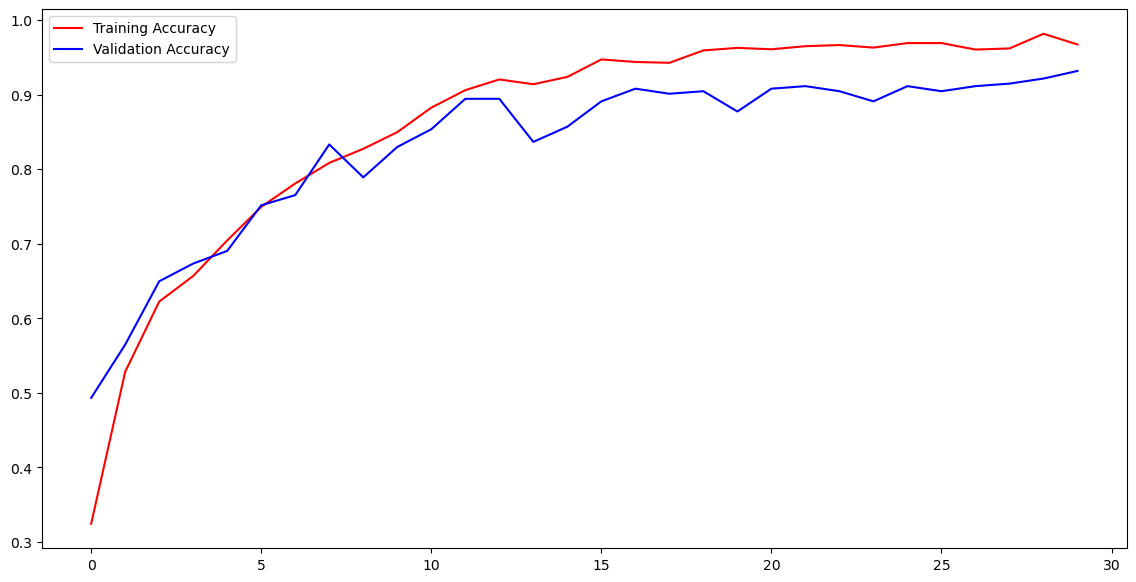

In [13]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(len(acc))
fig = plt.figure(figsize=(14,7))
plt.plot(epochs,acc,'r',label="Training Accuracy")
plt.plot(epochs,val_acc,'b',label="Validation Accuracy")
plt.legend(loc='upper left')
plt.show()

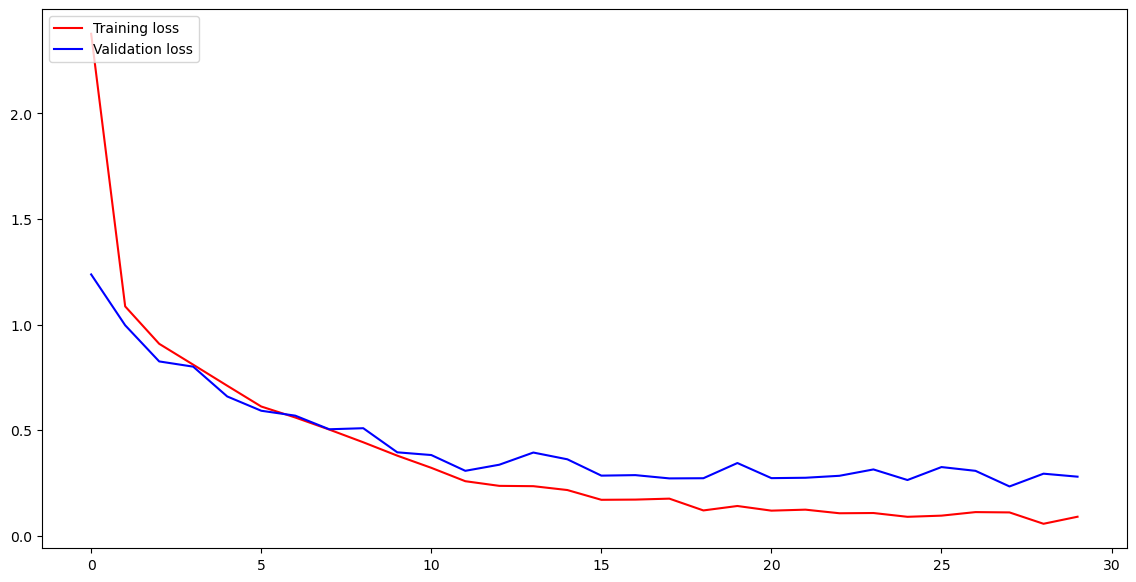

In [14]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(len(loss))
fig = plt.figure(figsize=(14,7))
plt.plot(epochs,loss,'r',label="Training loss")
plt.plot(epochs,val_loss,'b',label="Validation loss")
plt.legend(loc='upper left')
plt.show()

In [15]:
#prediction
img = cv2.imread('../JUPYTERNOTEBOOK/Data/Testing/glioma_tumor/image(6).jpg')
img = cv2.resize(img,(150,150))
img_array = np.array(img)
img_array.shape

(150, 150, 3)

In [16]:
img_array = img_array.reshape(1,150,150,3)
img_array.shape

(1, 150, 150, 3)

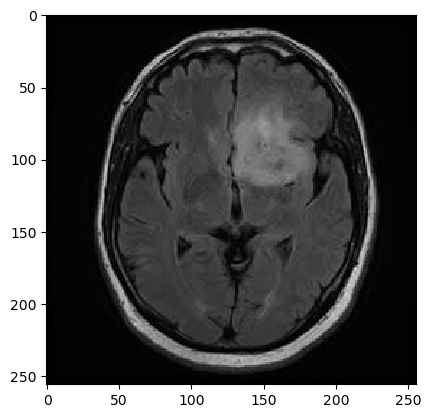

In [17]:
from tensorflow.keras.preprocessing import image
img = image.load_img('../JUPYTERNOTEBOOK/Data/Testing/glioma_tumor/image(6).jpg')
plt.imshow(img,interpolation='nearest')
plt.show()

In [18]:
a=model.predict(img_array)
indices = a.argmax()
indices

1/1 [==============================] - 1s 522ms/step


0

In [19]:
a=model.predict(img_array)
indices = a.argmax()
if indices == 0:
    print("glioma")
elif indices == 1:
    print("Meningioma")
elif indices == 2:
    print("No tumor")
elif indices == 3:
    print("Pituitary")

1/1 [==============================] - 0s 78ms/step
glioma


In [28]:
img = cv2.imread('../JUPYTERNOTEBOOK/Data/Testing/no_tumor/image(6).jpg')
img = cv2.resize(img,(150,150))
img_array = np.array(img)
img_array.shape

(150, 150, 3)

In [29]:
img_array = img_array.reshape(1,150,150,3)
img_array.shape

(1, 150, 150, 3)

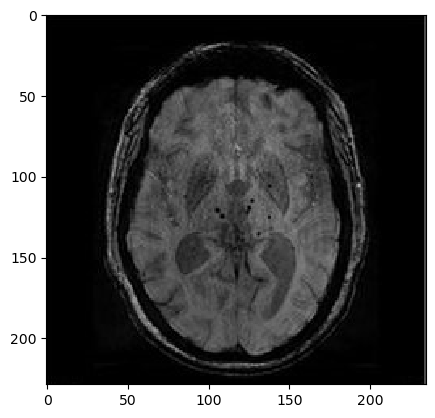

In [30]:
from tensorflow.keras.preprocessing import image
img = image.load_img('../JUPYTERNOTEBOOK/Data/Testing/no_tumor/image(6).jpg')
plt.imshow(img,interpolation='nearest')
plt.show()

In [31]:
a=model.predict(img_array)
indices = a.argmax()
indices

1/1 [==============================] - 0s 109ms/step


2

In [32]:
a=model.predict(img_array)
indices = a.argmax()
if indices == 0:
    print("glioma")
elif indices == 1:
    print("Meningioma")
elif indices == 2:
    print("No tumor")
elif indices == 3:
    print("Pituitary")

1/1 [==============================] - 0s 52ms/step
No tumor


In [33]:
from sklearn.metrics import confusion_matrix
import itertools

from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from keras.layers import BatchNormalization
from keras.optimizers import RMSprop,Adam,SGD,Adadelta
from keras.preprocessing.image import ImageDataGenerator

In [34]:
pip install django

Note: you may need to restart the kernel to use updated packages.


In [35]:
pred = model.predict(X_test)
pred = np.argmax(pred,axis=1)
y_test_new = np.argmax(y_test,axis=1)

11/11 [==============================] - 4s 359ms/step


In [21]:
from sklearn.metrics import classification_report,confusion_matrix
import ipywidgets as widgets

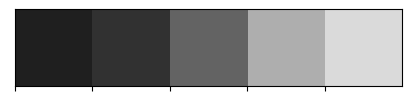

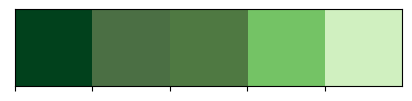

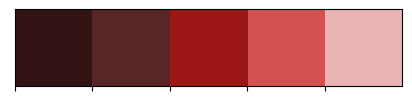

In [22]:
colors_dark = ["#1F1F1F", "#313131", '#636363', '#AEAEAE', '#DADADA']
colors_red = ["#331313", "#582626", '#9E1717', '#D35151', '#E9B4B4']
colors_green = ['#01411C','#4B6F44','#4F7942','#74C365','#D0F0C0']

sns.palplot(colors_dark)
sns.palplot(colors_green)
sns.palplot(colors_red)


In [23]:
pred = model.predict(X_test)
pred = np.argmax(pred,axis=1)
y_test_new = np.argmax(y_test,axis=1)

11/11 [==============================] - 7s 623ms/step


In [24]:
print(classification_report(y_test_new,pred))

              precision    recall  f1-score   support

           0       0.74      0.94      0.83        93
           1       0.94      0.69      0.80        95
           2       0.96      0.83      0.89        52
           3       0.91      0.99      0.95        87

    accuracy                           0.86       327
   macro avg       0.89      0.86      0.87       327
weighted avg       0.88      0.86      0.86       327



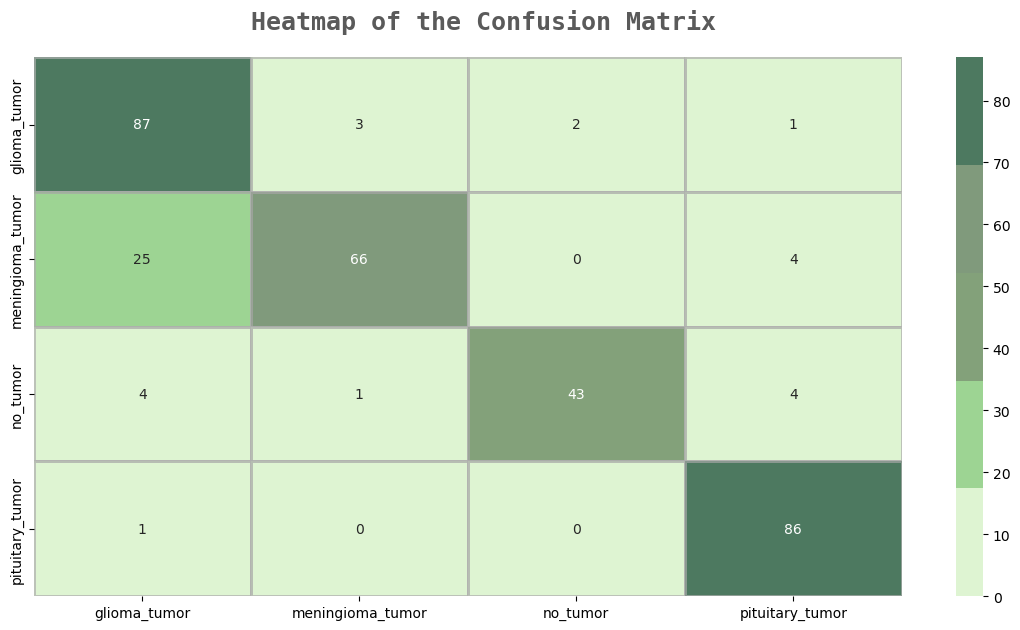

In [25]:
fig,ax=plt.subplots(1,1,figsize=(14,7))
sns.heatmap(confusion_matrix(y_test_new,pred),ax=ax,xticklabels=labels,yticklabels=labels,annot=True,
           cmap=colors_green[::-1],alpha=0.7,linewidths=2,linecolor=colors_dark[3])
fig.text(s='Heatmap of the Confusion Matrix',size=18,fontweight='bold',
             fontname='monospace',color=colors_dark[1],y=0.92,x=0.28,alpha=0.8)

plt.show()